# 5-1 描述统计：平均数会骗人

请选择 `Python (da-course)` 内核，从本包的 `notebooks/` 原位置打开。本课用随包模拟订单 `orders.csv`（2025 全年 15115 笔，先筛已完成 13996 笔）和 `books.csv`，体会为什么只报一个平均数很容易误导判断。

> **这是参考答案版**，保留完整示例与解法。代码格下方的输出会在运行后出现。
> 建议先在 `notebooks/` 文件夹里的学生版自己做一遍，卡住了再来这里对照。

In [1]:
import sys
sys.path.insert(0, "..")
from dacheck import check, hint, setup_chinese_font
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

读取原始表，先筛出已完成订单。已完成订单的实付金额用于本课教学，不等于财务净利润。

In [2]:
orders = pd.read_csv("../data/shop/orders.csv", encoding="utf-8-sig")
books = pd.read_csv("../data/books.csv", encoding="utf-8-sig")
completed = orders.loc[orders["status"].eq("已完成")].copy()
print("已完成订单数：", len(completed), "图书数：", len(books))

已完成订单数： 13996 图书数： 200


## 1. 平均数 vs 中位数：少数大单如何拉高均值

In [3]:
pay = completed["pay_amount"]
print(f"均值 mean   = {pay.mean():.2f} 元")
print(f"中位数 median = {pay.median():.2f} 元")
print(f"众数 mode   = {pay.mode().iloc[0]:.2f} 元")
print(f"标准差 std  = {pay.std():.2f} 元")

均值 mean   = 127.49 元
中位数 median = 79.00 元
众数 mode   = 15.00 元
标准差 std  = 132.10 元


均值 127.49 元比中位数 79.00 元高出 61%，说明订单金额呈现明显的**右偏分布**：大多数订单金额在几十元到一百多元，少数多件高价订单把平均值拉高了。

## 2. 分位数与四分位距（IQR）

In [4]:
q = pay.quantile([0.25, 0.50, 0.75, 0.90, 0.95])
print(q)
iqr = q.loc[0.75] - q.loc[0.25]
print(f"四分位距 IQR = Q3 - Q1 = {iqr:.2f} 元")

0.25     44.0
0.50     79.0
0.75    159.0
0.90    297.0
0.95    396.0
Name: pay_amount, dtype: float64
四分位距 IQR = Q3 - Q1 = 115.00 元


画一张直方图，把均值和中位数标在同一张图上，直观感受偏态分布。

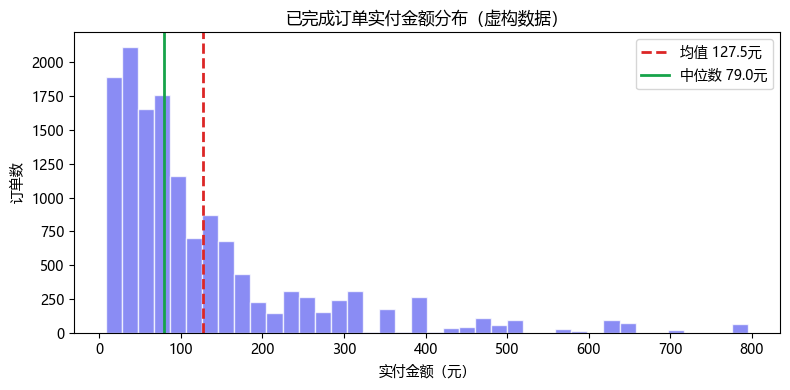

In [5]:
setup_chinese_font()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(pay, bins=40, color="#6366f1", alpha=0.75, edgecolor="white")
ax.axvline(pay.mean(), color="#dc2626", linestyle="--", linewidth=2, label=f"均值 {pay.mean():.1f}元")
ax.axvline(pay.median(), color="#16a34a", linestyle="-", linewidth=2, label=f"中位数 {pay.median():.1f}元")
ax.set(title="已完成订单实付金额分布（虚构数据）", xlabel="实付金额（元）", ylabel="订单数")
ax.legend()
fig.tight_layout()
plt.show()

## 3. 分组后也要同时看均值和中位数

In [6]:
completed.groupby("platform", as_index=False).agg(
    mean=("pay_amount", "mean"),
    median=("pay_amount", "median"),
    std=("pay_amount", "std"),
).round(2)

,platform,mean,median,std
0,微信小程序,128.32,79.0,133.25
1,抖音小店,130.60,79.0,135.48
2,淘宝,125.37,79.0,129.56


三个平台的中位数都是 79.0 元，但均值和标准差不同，说明差异主要来自高额订单的尾部。

## 练习 5-1.1 已完成订单金额核心描述统计

从 `orders` 独立筛选 `status == "已完成"`，计算 `pay_amount` 的均值、中位数、标准差（默认 `ddof=1`）和四分位距 `IQR = Q3 - Q1`，放入 4 键字典 `desc_answer`。

In [7]:
s = orders.loc[orders["status"].eq("已完成"), "pay_amount"]
desc_answer = {
    "mean": s.mean(),
    "median": s.median(),
    "std": s.std(),
    "iqr": s.quantile(0.75) - s.quantile(0.25),
}
check("5-1.1", desc_answer)

True

## 练习 5-1.2 订单金额分位数

计算已完成订单 `pay_amount` 的 `P50`、`P75`、`P90`、`P95`，存入字典 `q_answer`（键名 `p50`、`p75`、`p90`、`p95`）。

In [8]:
s = orders.loc[orders["status"].eq("已完成"), "pay_amount"]
q_answer = {
    "p50": s.quantile(0.50),
    "p75": s.quantile(0.75),
    "p90": s.quantile(0.90),
    "p95": s.quantile(0.95),
}
check("5-1.2", q_answer)

True

## 练习 5-1.3 各平台实付金额的均值、中位数与标准差

从 `orders` 筛选已完成订单，按 `platform` 分组（`as_index=False`），计算 `mean`、`median`、`std`，按 `platform` 升序排列，提交原始精度结果。

In [9]:
done = orders.loc[orders["status"].eq("已完成")]
plat_answer = (
    done.groupby("platform", as_index=False)
    .agg(
        mean=("pay_amount", "mean"),
        median=("pay_amount", "median"),
        std=("pay_amount", "std"),
    )
    .sort_values("platform")
    .reset_index(drop=True)
)
check("5-1.3", plat_answer)

True

## 练习 5-1.4 用 IQR 规则统计图书评价人数上侧离群数

对 `books["rating_count"]` 计算 `Q1`、`Q3` 和 `IQR = Q3 - Q1`，统计大于 `Q3 + 1.5 * IQR` 的图书数量（整数）。注意：统计离群点不自动等于错误记录。

In [10]:
rc = books["rating_count"]
q1, q3 = rc.quantile(0.25), rc.quantile(0.75)
outlier_count = int((rc > q3 + 1.5 * (q3 - q1)).sum())
check("5-1.4", outlier_count)

True